# 3. Classification — Predicting `target_class`
**APRAU 2026/27 — Group 18**

Methods: Logistic Regression and Linear Discriminant Analysis (LDA)

Resampling: Holdout | CV k=5 | CV k=10 | LOOCV | Bootstrap

## 1. Setup

In [1]:
import sys
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATASET_PATH = '/content/drive/MyDrive/APRAU/dataset_grupo_18.csv'
else:
    DATASET_PATH = '../dataset_grupo_18.csv'

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import (
    train_test_split, cross_val_score,
    LeaveOneOut, StratifiedKFold
)
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.utils import resample

plt.rcParams['figure.figsize'] = (10, 5)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 2. Data Loading & Preprocessing

In [3]:
df = pd.read_csv(DATASET_PATH)

df_enc = df.copy()
le = LabelEncoder()
for col in df_enc.select_dtypes(include='object').columns:
    df_enc[col] = le.fit_transform(df_enc[col].astype(str))

TARGET = 'target_class'
FEATURES = [c for c in df_enc.columns if c not in [TARGET, 'target_regression']]

X = df_enc[FEATURES].values
y = df_enc[TARGET].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f'X: {X_scaled.shape} | Classes: {np.unique(y)}')

X: (2000, 33) | Classes: [0 1 2]


In [4]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'LDA': LinearDiscriminantAnalysis()
}

results = []

def record(model_name, method, scores):
    results.append({
        'Model': model_name,
        'Method': method,
        'Mean Accuracy': np.mean(scores),
        'Std': np.std(scores)
    })

## 3. Holdout

Logistic Regression — Holdout Accuracy: 0.9175
              precision    recall  f1-score   support

           0       0.89      0.92      0.91        93
           1       0.00      0.00      0.00        17
           2       0.93      0.97      0.95       290

    accuracy                           0.92       400
   macro avg       0.61      0.63      0.62       400
weighted avg       0.88      0.92      0.90       400



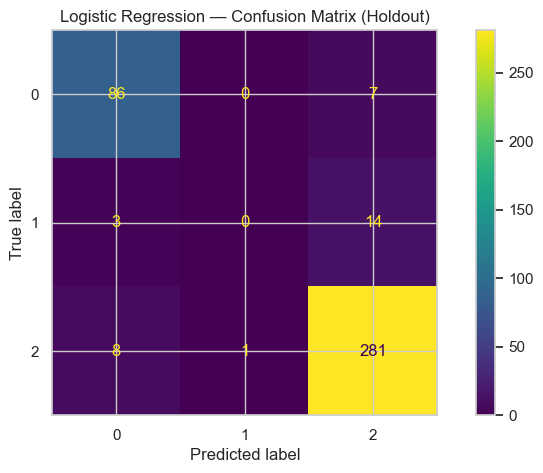

LDA — Holdout Accuracy: 0.8925
              precision    recall  f1-score   support

           0       0.90      0.83      0.86        93
           1       0.20      0.06      0.09        17
           2       0.90      0.96      0.93       290

    accuracy                           0.89       400
   macro avg       0.67      0.62      0.63       400
weighted avg       0.87      0.89      0.88       400



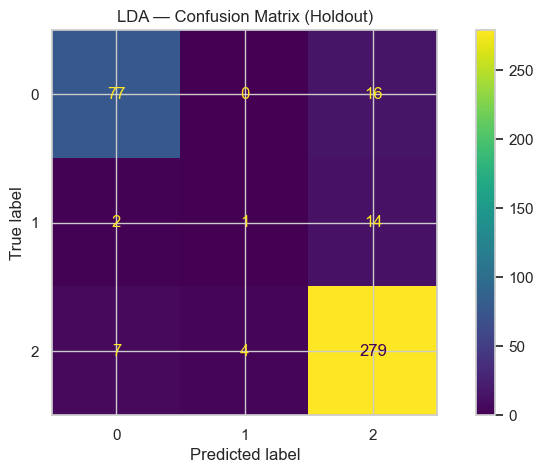

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    record(name, 'Holdout', [acc])
    print(f'{name} — Holdout Accuracy: {acc:.4f}')
    print(classification_report(y_test, y_pred))

    disp = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
    disp.plot()
    plt.title(f'{name} — Confusion Matrix (Holdout)')
    plt.show()

## 4. Cross-Validation (k=5 and k=10)

In [6]:
for k in [5, 10]:
    cv = StratifiedKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)
    for name, model in models.items():
        scores = cross_val_score(model, X_scaled, y, cv=cv, scoring='accuracy')
        record(name, f'CV k={k}', scores)
        print(f'{name} — CV k={k}: {np.mean(scores):.4f} ± {np.std(scores):.4f}')

Logistic Regression — CV k=5: 0.9015 ± 0.0094
LDA — CV k=5: 0.8860 ± 0.0150
Logistic Regression — CV k=10: 0.9015 ± 0.0112
LDA — CV k=10: 0.8890 ± 0.0148


## 5. Leave-One-Out Cross-Validation (LOOCV)

In [7]:
# LOOCV is slow for large datasets — consider subsampling if needed
loo = LeaveOneOut()
for name, model in models.items():
    scores = cross_val_score(model, X_scaled, y, cv=loo, scoring='accuracy')
    record(name, 'LOOCV', scores)
    print(f'{name} — LOOCV: {np.mean(scores):.4f} ± {np.std(scores):.4f}')

Logistic Regression — LOOCV: 0.9030 ± 0.2960
LDA — LOOCV: 0.8910 ± 0.3116


## 6. Bootstrap

In [8]:
N_BOOTSTRAP = 100

for name, model in models.items():
    boot_scores = []
    for i in range(N_BOOTSTRAP):
        X_boot, y_boot = resample(X_scaled, y, random_state=i)
        # OOB indices
        oob_mask = np.ones(len(X_scaled), dtype=bool)
        boot_idx = np.unique(resample(np.arange(len(X_scaled)), random_state=i))
        oob_mask[boot_idx] = False
        if oob_mask.sum() == 0:
            continue
        model.fit(X_boot, y_boot)
        acc = accuracy_score(y[oob_mask], model.predict(X_scaled[oob_mask]))
        boot_scores.append(acc)
    record(name, 'Bootstrap', boot_scores)
    print(f'{name} — Bootstrap: {np.mean(boot_scores):.4f} ± {np.std(boot_scores):.4f}')

Logistic Regression — Bootstrap: 0.8985 ± 0.0094
LDA — Bootstrap: 0.8814 ± 0.0116


## 7. Results Summary

In [9]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(['Model', 'Mean Accuracy'], ascending=[True, False])
results_df

,Model,Method,Mean Accuracy,Std
1,LDA,Holdout,0.892500,0.000000
7,LDA,LOOCV,0.891000,0.311639
5,LDA,CV k=10,0.889000,0.014799
3,LDA,CV k=5,0.886000,0.014967
9,LDA,Bootstrap,0.881360,0.011554
0,Logistic Regression,Holdout,0.917500,0.000000
6,Logistic Regression,LOOCV,0.903000,0.295958
2,Logistic Regression,CV k=5,0.901500,0.009434
4,Logistic Regression,CV k=10,0.901500,0.011192
8,Logistic Regression,Bootstrap,0.898475,0.009392


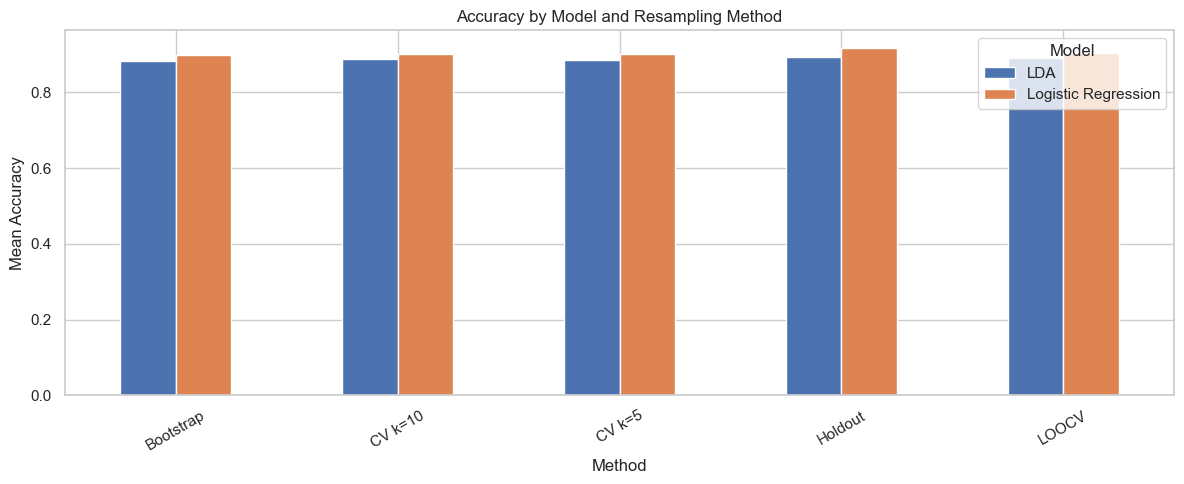

In [10]:
pivot = results_df.pivot(index='Method', columns='Model', values='Mean Accuracy')
pivot.plot(kind='bar', figsize=(12, 5))
plt.title('Accuracy by Model and Resampling Method')
plt.ylabel('Mean Accuracy')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Discussion

*(Fill in after running the models)*

- **Best method/model combination:**
- **How variance changes across resampling methods:**
- **LR vs LDA — which is more appropriate and why:**